In [ ]:
import pickle

with open('../G2CP/results/LINCS_pairwise_perturbagen_unipert_similarity.pkl', 'rb') as f:
    all_sim = pickle.load(f)
    gene_gene, gene_chem, chem_chem = all_sim['gene_gene'], all_sim['gene_chem'], all_sim['chem_chem']

In [ ]:
len(gene-gene), len(gene_chem), len(chem_chem)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns

font_path = "../Helvetica.ttf"
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.4,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name]   
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"

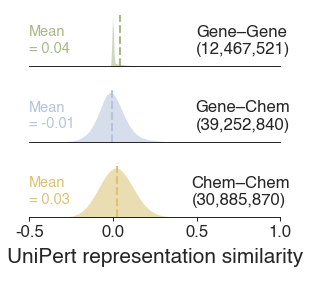

In [3]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(2.2, 2), sharex=True)

plot_info = [
    (gene_gene, '#a8b987', 'Gene–Gene\n(12,467,521)', ax1),
    (gene_chem, '#B7C3DC', 'Gene–Chem\n(39,252,840)', ax2),
    (chem_chem, '#dcc273', 'Chem–Chem\n(30,885,870)', ax3),
]

for df_part, color, label, ax in plot_info:
    sample = df_part['UniPert similarity'].sample(n=len(df_part), random_state=1)
    mean_val = sample.mean()

    sns.kdeplot(
        data=sample,
        color=color,
        fill=True,
        alpha=0.55,
        linewidth=0,
        ax=ax,
        label=label
    )

 
    ax.axvline(mean_val, color=color, linestyle='--', linewidth=1.0)
    ax.text(
        -0.5,
        ax.get_ylim()[1] * 0.8,
        f"Mean\n= {mean_val:.2f}",
        color=color,
        fontsize=7,
        ha='left',
        va='top',
        rotation=0,
    )

    ax.set_yticks([])
    sns.despine(ax=ax)
    ax.spines['left'].set_visible(False)
    ax.legend(
        frameon=False,
        handlelength=0,
        bbox_to_anchor=(1.1, 0.5),
        loc='center right',
    )
    ax.tick_params(direction='out', length=2, width=0.5, pad=1.5, labelsize=8)

xlim = (-0.5, 1.0)
for ax in [ax1, ax2, ax3]:
    ax.set_xlim(xlim)

ax1.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
ax2.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
ax3.set_xticks([-0.5, 0, 0.5, 1])
ax3.set_xticklabels(['-0.5', '0.0', '0.5', '1.0'])
ax3.set_xlabel('UniPert representation similarity', labelpad=4, fontsize=10)

ax1.set_ylabel('')
ax2.set_ylabel('')
ax3.set_ylabel('')

plt.tight_layout()
plt.show()